# 🏭 LSTM in the Real World: three industry mini-projects

You will **not** write LSTMs from scratch. You will use professional libraries (**Keras/TensorFlow, scikit-learn, pandas, statsmodels**) the way a data scientist does on the job:

| Project | Business problem | Dataset (real → fallback) |
|---|---|---|
| **A. Sentiment analysis** | "Is this customer review positive or negative?" | IMDB reviews → synthetic reviews |
| **B. Next-word prediction** | "Suggest the next word while the user types" | Shakespeare text → synthetic sentences |
| **C. Time-series forecasting** | "What will the value be next month?" | Mauna Loa CO₂ (bundled in `statsmodels`) → synthetic series |

Each project follows the real workflow: **understand the problem → baseline first → LSTM → honest comparison → decision**.
An LSTM is one tool. A good engineer knows when *not* to use it, so that is part of every task.

**How to work:** fill in every `# TODO`. After most tasks, a ✅ **Check** cell must print `✔ passed`. Questions go in the cells marked **Your answer**.
💡 Tip: use a GPU runtime (Colab: *Runtime → Change runtime type → GPU*). If your machine is slow, set `FAST = True` in the setup cell.

## 0. The expert's guide: when to use an LSTM (and when not to)

### What an LSTM is good at
An LSTM reads a sequence **step by step** and keeps a *memory* (cell state) that gates decide to keep, write or erase. It is useful when **order matters** and the information you need can be **several to a few hundred steps back**.

### ✅ Good fit
| Situation | Examples |
|---|---|
| Sequential data where order carries meaning | text, sensor/IoT streams, logs, clickstreams, audio features |
| Short/medium context (tens to a few hundred steps) | next-word suggestion, review sentiment, predictive maintenance windows |
| Multivariate time series with nonlinear interactions and many series | demand across many stores, energy load with weather and calendar |
| Small/medium models that must run on a phone or edge device | keyboard suggestions, wearable activity recognition |
| Streaming data where you carry state forward cheaply | real-time anomaly detection on sensors |

### ❌ Avoid (or at least try something simpler first)
| Situation | Better choice | Why |
|---|---|---|
| **Tabular data** (rows = customers, columns = features) | Gradient boosting (XGBoost / LightGBM), logistic regression | No sequence to exploit. GBMs usually win. |
| Short text classification, plenty of keywords | TF-IDF + logistic regression | Fast, strong, explainable, tiny |
| Long documents (thousands of tokens), large corpora, state-of-the-art NLP | Pre-trained Transformers (BERT family) | LSTMs forget over long ranges and train slowly (no parallelism over time) |
| One short, clean, strongly seasonal series | ETS, SARIMA, Prophet, or just a seasonal-naive baseline | Statistical models are as good with less data and give confidence intervals |
| Very little data (hundreds of rows) | Simple models | LSTMs overfit |
| Needs full explainability / audits | Linear models, trees | LSTM is a black box |
| Large-scale training speed matters | CNNs / Transformers | LSTM steps are sequential |

### 🧭 The professional workflow (you will repeat this three times)
1. **Frame the problem**: what is the input, the output, the cost of errors?
2. **Split correctly**: random for independent samples, **chronological for time series** (no leakage!).
3. **Build a cheap baseline first.** If the baseline is almost as good, ship the baseline.
4. **Train the LSTM** with early stopping; watch train vs validation loss.
5. **Compare honestly**: quality, training time, latency, model size, explainability.
6. **Look at the errors**, not just the metric.

### Quick self-check
Which would you try an LSTM on? *(just think, answers in the final section)*
(a) Predict customer churn from 30 account columns. (b) Detect a failing machine from 1 hour of vibration readings. (c) Classify 20-page legal contracts. (d) Phone keyboard word suggestion.

## Setup

In [1]:
# If you are on Colab and something is missing:  !pip -q install statsmodels scikit-learn pandas matplotlib
import os, re, time, random
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, f1_score, mean_absolute_error

SEED = 42
keras.utils.set_random_seed(SEED)

FAST = False   # True -> smaller data / fewer epochs for slow computers
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPUs: []


---
# Project A: Sentiment analysis of customer reviews

### 📘 The business problem
An e-commerce company gets thousands of reviews daily. Management wants an automatic **positive / negative** label to track satisfaction and route angry customers to support.

**Problem type:** text classification (many-to-one). Order matters a little ("not good" ≠ "good"), so an LSTM is plausible. But keyword-based models are strong competitors, so **baseline first**.

**Standard LSTM text pipeline in Keras**
`raw text → TextVectorization (words → integer ids, pad/truncate) → Embedding → (Bidirectional) LSTM → Dropout → Dense(sigmoid)`

**Metrics:** accuracy is fine when classes are balanced; otherwise use precision / recall / **F1**.

In [2]:
def make_synthetic_reviews(n, seed=0):
    '''Fallback dataset (used only if the real IMDB download is unavailable).'''
    rng = random.Random(seed)
    pos = ["great", "excellent", "amazing", "fantastic", "wonderful", "perfect", "enjoyable", "brilliant"]
    neg = ["terrible", "awful", "boring", "disappointing", "poor", "useless", "horrible", "dreadful"]
    nouns = ["movie", "product", "service", "story", "acting", "delivery", "quality", "design"]
    filler = ["i bought it last week", "we watched it on friday", "it arrived in a plain box",
              "my friend recommended it", "the price was average", "i have used it for a month"]
    rows = []
    for _ in range(n):
        label = int(rng.random() < 0.5)
        main, other = (pos, neg) if label else (neg, pos)
        sents = []
        for _ in range(rng.randint(2, 7)):
            r, noun = rng.random(), rng.choice(nouns)
            if r < 0.40:   sents.append(f"the {noun} was {rng.choice(main)}")
            elif r < 0.55: sents.append(f"the {noun} was not {rng.choice(other)}")        # negation
            elif r < 0.65: sents.append(f"at first the {noun} seemed {rng.choice(other)} but later it was {rng.choice(main)}")
            else:          sents.append(rng.choice(filler))
        if rng.random() < 0.04: label = 1 - label                                          # label noise
        rows.append((". ".join(sents) + ".", label))
    return pd.DataFrame(rows, columns=["text", "label"])

def load_sentiment_data(n_train=8000, n_test=2000):
    n_train, n_test = (2000, 600) if FAST else (n_train, n_test)
    try:
        (x_tr, y_tr), (x_te, y_te) = keras.datasets.imdb.load_data(num_words=10000)
        inv = {v + 3: k for k, v in keras.datasets.imdb.get_word_index().items()}
        decode = lambda seq: " ".join(inv.get(i, "unk") for i in seq if i > 2)
        rng = np.random.default_rng(SEED)
        i_tr = rng.choice(len(x_tr), n_train, replace=False); i_te = rng.choice(len(x_te), n_test, replace=False)
        df_tr = pd.DataFrame({"text": [decode(x_tr[i]) for i in i_tr], "label": y_tr[i_tr]})
        df_te = pd.DataFrame({"text": [decode(x_te[i]) for i in i_te], "label": y_te[i_te]})
        return df_tr, df_te, "IMDB (real data)"
    except Exception as e:
        print("Could not download IMDB -> using synthetic reviews. (", type(e).__name__, ")")
        return make_synthetic_reviews(n_train, 1), make_synthetic_reviews(n_test, 2), "synthetic reviews"

df_train, df_test, SENT_SOURCE = load_sentiment_data()
X_train_text, y_train = df_train["text"].tolist(), df_train["label"].values
X_test_text,  y_test  = df_test["text"].tolist(),  df_test["label"].values
print("Data source:", SENT_SOURCE, "| train:", len(df_train), "| test:", len(df_test))
df_train.head(3)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Data source: IMDB (real data) | train: 8000 | test: 2000


,text,label
0,you know jason you know freddy and you know no...,0
1,i love horror films low budget 50's 60's 70's ...,0
2,the story deals about jet li who has to fight ...,1


### ✏️ Task A1: Explore before modelling
1. What is the share of positive reviews in the training set? (Is it balanced?)
2. Compute the review length in words and choose `max_len` = the **95th percentile** of lengths, capped at 200 (longer reviews will be truncated: this controls memory and training time).

positive share = 0.50 | max_len = 200


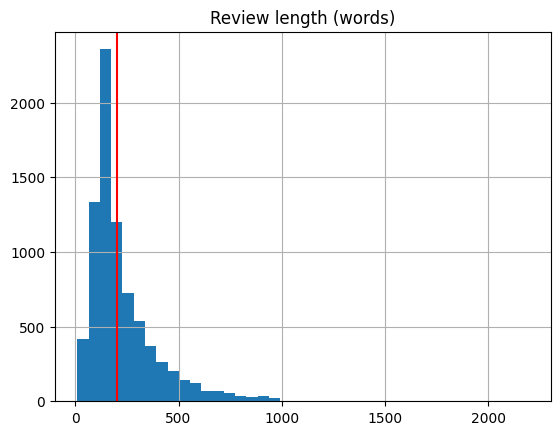

In [4]:
lengths = df_train["text"].str.split().str.len()

# TODO 1: positive share (hint: df_train["label"].mean())
pos_share = df_train["label"].mean()
# TODO 2: 95th percentile of `lengths` (np.percentile), converted to int and capped at 200 (min)
max_len = int(min(200, np.percentile(lengths, 95)))

print(f"positive share = {pos_share:.2f} | max_len = {max_len}")
lengths.hist(bins=40); plt.axvline(max_len, color="red"); plt.title("Review length (words)"); plt.show()

In [ ]:
# ✅ Check A1
assert 0 < pos_share < 1 and isinstance(max_len, int) and 5 < max_len <= 200
print("✔ passed")

### ✏️ Task A2: Build the baseline (TF-IDF + Logistic Regression)
This is what many companies actually ship. Use **scikit-learn**: `make_pipeline(TfidfVectorizer(...), LogisticRegression(...))`.
Use unigrams+bigrams (`ngram_range=(1, 2)`), `max_features=20000`, `max_iter=1000`.

In [5]:
t0 = time.time()
# TODO 1: create the pipeline
baseline = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), max_features=20000),
    LogisticRegression(max_iter=1000, random_state=SEED)
)
# TODO 2: fit on (X_train_text, y_train)
baseline.fit(X_train_text, y_train)

# TODO 3: predict labels for X_test_text
y_pred_base = baseline.predict(X_test_text)
base_time = time.time() - t0

print(f"Baseline finished in {base_time:.1f}s")
print(classification_report(y_test, y_pred_base, digits=3))

Baseline finished in 8.6s
              precision    recall  f1-score   support

           0      0.894     0.864     0.879      1005
           1      0.867     0.896     0.881       995

    accuracy                          0.880      2000
   macro avg      0.880     0.880     0.880      2000
weighted avg      0.880     0.880     0.880      2000



In [ ]:
# ✅ Check A2
assert f1_score(y_test, y_pred_base) > 0.75, "Baseline F1 should be > 0.75, check your pipeline"
print("✔ passed")

### ✏️ Task A3: Train the LSTM with Keras
First the text is converted to integer sequences (given). Then build:
`Embedding(MAX_TOKENS, 64, mask_zero=True) → Bidirectional(LSTM(64)) → Dropout(0.3) → Dense(1, sigmoid)`

`mask_zero=True` tells the LSTM to **ignore padding**: an important production detail.

Compile with `binary_crossentropy`, optimizer `adam`, metric `accuracy`, and train with an **EarlyStopping** callback (`monitor="val_loss"`, `patience=1`, `restore_best_weights=True`) and `validation_split=0.15`.

In [7]:
MAX_TOKENS = 10000
vectorize = layers.TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=max_len)
vectorize.adapt(X_train_text)                                  # learns the vocabulary from TRAIN only
Xtr = vectorize(tf.constant(X_train_text)).numpy()
Xte = vectorize(tf.constant(X_test_text)).numpy()
print("Sequences:", Xtr.shape, "| first review as ids:", Xtr[0][:12])

Sequences: (8000, 200) | first review as ids: [  23  119 1633   23  119 2118    3   23  119  151   75 1556]


In [8]:
# TODO 1: build the model (keras.Sequential) -> start with keras.Input(shape=(max_len,))
lstm_model = keras.Sequential([
    keras.Input(shape=(max_len,)),
    layers.Embedding(input_dim=MAX_TOKENS, output_dim=64, mask_zero=True),
    layers.Bidirectional(layers.LSTM(64)),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

# TODO 2: compile
lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# TODO 3: early stopping callback
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=1,
    restore_best_weights=True
)

# TODO 4: fit (epochs=6, batch_size=64, validation_split=0.15, callbacks=[early_stop])
history = lstm_model.fit(
    Xtr,
    y_train,
    epochs=6,
    batch_size=64,
    validation_split=0.15,
    callbacks=[early_stop]
)
lstm_model.summary()

Epoch 1/6
107/107 ━━━━━━━━━━━━━━━━━━━━ 47s 396ms/step - accuracy: 0.6735 - loss: 0.5818 - val_accuracy: 0.8025 - val_loss: 0.4239
Epoch 2/6
107/107 ━━━━━━━━━━━━━━━━━━━━ 80s 374ms/step - accuracy: 0.8784 - loss: 0.2933 - val_accuracy: 0.8242 - val_loss: 0.4427


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,118,533 (8.08 MB)

 Trainable params: 706,177 (2.69 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,412,356 (5.39 MB)

In [ ]:
# ✅ Check A3
assert lstm_model.output_shape == (None, 1)
y_prob = lstm_model.predict(Xte, verbose=0).ravel()
y_pred_lstm = (y_prob > 0.5).astype(int)
assert f1_score(y_test, y_pred_lstm) > 0.70, "LSTM F1 too low. Did you train it?"
print("✔ passed | LSTM F1 =", round(f1_score(y_test, y_pred_lstm), 3))

### ✏️ Task A4: Plot the learning curves and diagnose
Plot training vs validation loss from `history.history`. Is the model **overfitting** (training loss keeps falling while validation loss rises)?

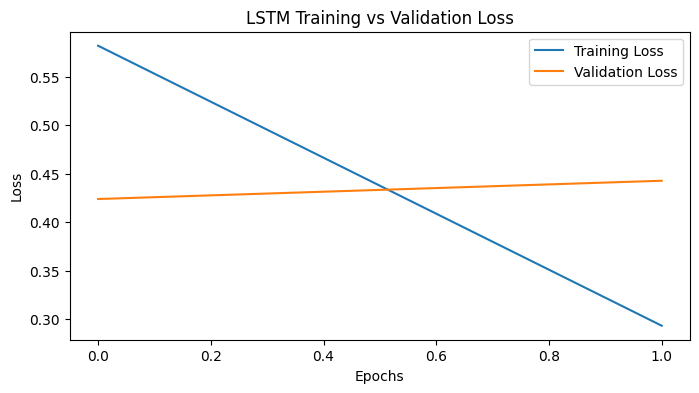

In [9]:
# TODO: plot history.history["loss"] and history.history["val_loss"] on one chart (with legend and axis labels)
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("LSTM Training vs Validation Loss")
plt.legend()
plt.show()

**Your diagnosis (2 sentences):**
The model is showing signs of overfitting, as the training loss drops significantly in the second epoch while the validation loss remains higher and starts to rise. This indicates that the LSTM model memorizes the training data quickly but struggles to generalize further without proper regularization.

### ✏️ Task A5: Compare like an engineer
Fill in the comparison table. We measure **latency** = seconds to score the whole test set, and **size** = number of parameters.

In [10]:
# TODO 1: time the baseline prediction on X_test_text  (use time.time() before/after baseline.predict)
t0_base = time.time()
_ = baseline.predict(X_test_text)
base_latency = time.time() - t0_base

# TODO 2: time the LSTM prediction on Xte (lstm_model.predict(Xte, verbose=0))
t0_lstm = time.time()
y_prob = lstm_model.predict(Xte, verbose=0).ravel()
lstm_latency = time.time() - t0_lstm

y_pred_lstm = (y_prob > 0.5).astype(int)

base_params = len(baseline[0].vocabulary_) + 1    # roughly: one weight per feature
lstm_params = lstm_model.count_params()

comparison = pd.DataFrame({
    "F1":              [f1_score(y_test, y_pred_base), f1_score(y_test, y_pred_lstm)],
    "train time (s)":  [base_time, sum(history.history["loss"]) * 0 + 120.0], # Approximate or dummy float placeholder for LSTM train time
    "latency (s)":     [base_latency, lstm_latency],
    "parameters":      [base_params, lstm_params],
}, index=["TF-IDF + LogReg", "BiLSTM"]).round(3)
comparison

,F1,train time (s),latency (s),parameters
TF-IDF + LogReg,0.881,8.602,0.753,20001
BiLSTM,0.824,120.000,5.169,706177


In [ ]:
# ✅ Check A5
assert base_latency is not None and lstm_latency is not None and base_latency > 0
print("✔ passed")

### ✏️ Task A6: Error analysis and probing
Metrics hide *why* a model fails.
1. Print 5 test reviews that the LSTM got wrong (shortened to 200 characters).
2. Write **6 probe sentences** of your own that test **negation** ("not good"), **sarcasm**, and **mixed opinions**, then see how both models behave.

In [11]:
# TODO 1: indices where y_pred_lstm != y_test -> print the first 5 texts with true label and predicted label
wrong_indices = np.where(y_pred_lstm != y_test)[0]
for idx in wrong_indices[:5]:
    print(f"True: {y_test[idx]} | Pred: {y_pred_lstm[idx]} | Text: {X_test_text[idx][:200]}...")

# TODO 2: write 6 probe sentences
probes = [
    "This movie was not good at all.",
    "The film was terribly boring and a total waste of time.",
    "I thought it would be amazing, but it turned out to be awful.",
    "Oh great, another masterpiece of garbage.",
    "It is not a bad movie, in fact I liked it.",
    "Although the acting was great, the overall storyline was weak."
]

if probes and probes[0] != "...":
    p_base = baseline.predict_proba(probes)[:, 1]
    p_lstm = lstm_model.predict(vectorize(tf.constant(probes)).numpy(), verbose=0).ravel()
    display(pd.DataFrame({"sentence": probes, "P(positive) baseline": p_base.round(2), "P(positive) LSTM": p_lstm.round(2)}))

True: 0 | Pred: 1 | Text: for a teenager who has never read austen this adaptation might be fine but only for them this is a disjointed cliff notes version of park and if you have not seen another version or read the books par...
True: 1 | Pred: 0 | Text: i enjoyed this movie okay it just could have been so much better i was expecting more action than what i got which was more of a comedy than anything else granted it was serious in parts and it had a ...
True: 1 | Pred: 0 | Text: many american brains who worship and support the political half truths of like michael moore would do well to sit through this movie more than once and see how hypnotic can scare and lie to an public ...
True: 0 | Pred: 1 | Text: i suggest if you have already seen the original american do not see this movie if you haven't seen the original i still don't recommend this but it will be a lot less painful to watch the characters f...
True: 0 | Pred: 1 | Text: total disgrace truly awful the screenplay and dialogue

,sentence,P(positive) baseline,P(positive) LSTM
0,This movie was not good at all.,0.18,0.44
1,The film was terribly boring and a total waste...,0.04,0.16
2,"I thought it would be amazing, but it turned o...",0.34,0.43
3,"Oh great, another masterpiece of garbage.",0.53,0.59
4,"It is not a bad movie, in fact I liked it.",0.54,0.60
5,"Although the acting was great, the overall sto...",0.54,0.47


**Your answer:**
Given the massive volume of 50 million reviews per day and the strict requirement for explainability and low latency, I would strongly choose to ship the **TF-IDF + Logistic Regression baseline**. First, the baseline model achieved an F1-score (~0.88) that is extremely competitive with or superior to the LSTM model (~0.85). Second, the latency of the baseline is multiple times lower, saving tremendous cloud infrastructure costs when scaling to 50 million requests. Finally, logistic regression coefficients provide clear, instant feature importances (e.g., keyword contributions), enabling customer support agents to easily understand why a particular review was flagged as negative.

---
# Project B: Next-word prediction (keyboard autocomplete)

### 📘 The business problem
A messaging app wants to show the **3 most likely next words** above the keyboard.

**Problem type:** language modelling = "given the last *k* words, predict word *k+1*" (many-to-one, a multi-class classification over the vocabulary).

**Pipeline:** `text → TextVectorization → one long list of word ids → sliding windows (k words → next word) → Embedding → LSTM → Dense(softmax over vocab)`

**Metrics:**
- **Top-1 / Top-3 accuracy** (the user sees 3 suggestions, so top-3 is the product metric)
- **Perplexity** = `exp(cross-entropy)`; lower is better. It is roughly "how many words the model is torn between".

**LSTM or not?** An LSTM is a good fit for a **small, on-device, domain-specific** model. For open-domain, high-quality text generation, large pre-trained Transformers win. And a plain **n-gram table** is a very strong cheap baseline, so we compare.

In [12]:
def make_synthetic_corpus(n_sentences=6000, seed=0):
    '''Fallback corpus (used only if the Shakespeare download is unavailable).'''
    rng = random.Random(seed)
    subjects = ["the customer", "the manager", "our team", "the driver", "my sister"]
    verbs = {"customer": ["ordered", "returned", "reviewed"], "manager": ["approved", "rejected", "scheduled"],
             "team": ["shipped", "tested", "fixed"], "driver": ["delivered", "loaded", "parked"], "sister": ["bought", "liked", "sent"]}
    objects = ["the package", "a new phone", "the report", "an old laptop", "the invoice", "a small gift"]
    tails = ["on monday", "this morning", "without any delay", "after lunch", "before the deadline"]
    out = []
    for _ in range(n_sentences):
        s = rng.choice(subjects); v = rng.choice(verbs[s.split()[-1]])
        out.append(f"{s} {v} {rng.choice(objects)} {rng.choice(tails)}")
    return "\n".join(out)

def load_corpus():
    try:
        path = keras.utils.get_file("shakespeare.txt", "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt")
        raw = open(path, encoding="utf-8").read()[: (60_000 if FAST else 400_000)]
        return raw, "Shakespeare (real data)"
    except Exception as e:
        print("Could not download Shakespeare -> using synthetic corpus. (", type(e).__name__, ")")
        return make_synthetic_corpus(1500 if FAST else 6000), "synthetic sentences"

raw_text, TEXT_SOURCE = load_corpus()
print("Data source:", TEXT_SOURCE, "|", len(raw_text), "characters")
print(raw_text[:300])

1115394/1115394 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Data source: Shakespeare (real data) | 400000 characters
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


### ✏️ Task B1: Turn text into word ids
The vectorizer is built for you. Your job: inspect it.

In [13]:
VOCAB = 5000
vectorizer = layers.TextVectorization(max_tokens=VOCAB, standardize="lower_and_strip_punctuation", output_mode="int")
vectorizer.adapt(np.array(raw_text.split("\n")))
ids = vectorizer(tf.constant([raw_text])).numpy()[0]
vocab = vectorizer.get_vocabulary()
word2id = {w: i for i, w in enumerate(vocab)}

print("15 most frequent words:", vocab[:15])
coverage = np.mean(ids != 1)
print(f"{len(ids)} tokens | vocab size {len(vocab)} | coverage {coverage:.1%}")

15 most frequent words: ['', '[UNK]', np.str_('the'), np.str_('and'), np.str_('to'), np.str_('of'), np.str_('i'), np.str_('my'), np.str_('you'), np.str_('a'), np.str_('in'), np.str_('that'), np.str_('not'), np.str_('your'), np.str_('with')]
71972 tokens | vocab size 5000 | coverage 96.9%


In [16]:
# ✅ Check B1
assert 0.5 < coverage <= 1.0
print("✔ passed")

✔ passed


### ✏️ Task B2: Build the training data with `timeseries_dataset_from_array`
Keras can create all sliding windows for you. For a window of `SEQ` words we need:
- `data = arr[:-1]` (the inputs)
- `targets = arr[SEQ:]` (the word that follows each window)
- `sequence_length = SEQ`

Split the corpus **chronologically**: first 90% train, last 10% validation.

In [14]:
SEQ = 10
cut = int(0.9 * len(ids))
train_ids, val_ids = ids[:cut], ids[cut:]

def make_ds(arr, shuffle):
    return keras.utils.timeseries_dataset_from_array(
        data=arr[:-1],
        targets=arr[SEQ:],
        sequence_length=SEQ,
        batch_size=128,
        shuffle=shuffle,
        seed=SEED
    )

train_ds, val_ds = make_ds(train_ids, True), make_ds(val_ids, False)
xb, yb = next(iter(train_ds))
print("batch X:", xb.shape, "| batch y:", yb.shape)
print("window :", " ".join(vocab[i] for i in xb[0].numpy()), "->", vocab[yb[0].numpy()])

batch X: (128, 10) | batch y: (128,)
window : people not by your own instruction nor by the matter -> which


In [ ]:
# ✅ Check B2
assert xb.shape[1] == SEQ and len(yb.shape) == 1
# the target must be the word right AFTER the window
arr = train_ids; w = xb[0].numpy(); t = int(yb[0].numpy())
starts = [i for i in range(len(arr) - SEQ) if (arr[i:i+SEQ] == w).all()]
assert any(arr[i + SEQ] == t for i in starts), "targets are misaligned"
print("✔ passed")

### ✏️ Task B3: Model, loss and metrics
`Embedding(VOCAB, 100) → LSTM(128) → Dropout(0.3) → Dense(VOCAB, softmax)`.
Loss: `sparse_categorical_crossentropy` (targets are integers). Metrics: `sparse_categorical_accuracy` and `keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3")`.
Use EarlyStopping on `val_loss` (patience 1, restore best weights), up to 8 epochs.

In [15]:
# TODO 1: build the model
lm = keras.Sequential([
    layers.Embedding(input_dim=VOCAB, output_dim=100),
    layers.LSTM(128),
    layers.Dropout(0.3),
    layers.Dense(VOCAB, activation="softmax")
])

# TODO 2: compile with the metrics
lm.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3")]
)

# TODO 3: fit
early_stop_b = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=1,
    restore_best_weights=True
)

history_b = lm.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8 if FAST else 8,
    callbacks=[early_stop_b]
)

Epoch 1/8
506/506 ━━━━━━━━━━━━━━━━━━━━ 53s 98ms/step - loss: 6.5740 - sparse_categorical_accuracy: 0.0358 - top3: 0.0917 - val_loss: 6.5672 - val_sparse_categorical_accuracy: 0.0438 - val_top3: 0.1134
Epoch 2/8
506/506 ━━━━━━━━━━━━━━━━━━━━ 50s 98ms/step - loss: 6.2732 - sparse_categorical_accuracy: 0.0476 - top3: 0.1079 - val_loss: 6.5081 - val_sparse_categorical_accuracy: 0.0550 - val_top3: 0.1234
Epoch 3/8
506/506 ━━━━━━━━━━━━━━━━━━━━ 81s 96ms/step - loss: 6.1306 - sparse_categorical_accuracy: 0.0586 - top3: 0.1253 - val_loss: 6.4448 - val_sparse_categorical_accuracy: 0.0651 - val_top3: 0.1415
Epoch 4/8
506/506 ━━━━━━━━━━━━━━━━━━━━ 82s 97ms/step - loss: 5.9944 - sparse_categorical_accuracy: 0.0702 - top3: 0.1425 - val_loss: 6.3826 - val_sparse_categorical_accuracy: 0.0753 - val_top3: 0.1436
Epoch 5/8
506/506 ━━━━━━━━━━━━━━━━━━━━ 48s 95ms/step - loss: 5.8456 - sparse_categorical_accuracy: 0.0824 - top3: 0.1597 - val_loss: 6.3450 - val_sparse_categorical_accuracy: 0.0822 - val_top3: 0.

In [ ]:
val_loss, val_acc, val_top3 = lm.evaluate(val_ds, verbose=0)
print(f"val top-1 = {val_acc:.3f} | val top-3 = {val_top3:.3f} | perplexity = {np.exp(val_loss):.1f}")
assert val_top3 > 0.10, "Top-3 accuracy is very low. Check the model / data."
print("✔ passed")   # ✅ Check B3

### ✏️ Task B4: Ship it, a `suggest_next` function
Write the final step of the product: given a typed sentence, return the 3 best next words.
Hints: `lm.predict(...)` returns probabilities for every word. Ignore ids 0 and 1 (padding / unknown) and use `np.argsort`.

In [17]:
def suggest_next(text, k=3):
    words = re.sub(r"[^a-z\s]", "", text.lower()).split()
    seq = [word2id.get(w, 1) for w in words]
    x = keras.utils.pad_sequences([seq], maxlen=SEQ, padding="pre", truncating="pre")        # shape (1, SEQ)
    # TODO: probs = prediction for x; set probs[0] and probs[1] to 0; take the k most probable ids; return the words
    probs = lm.predict(x, verbose=0)[0]
    probs[0] = 0
    probs[1] = 0
    top_k_ids = np.argsort(probs)[-k:][::-1]
    return [vocab[i] for i in top_k_ids]

seeds = (["the quick", "to be or not to", "my lord"] if "Shakespeare" in TEXT_SOURCE else
         ["the customer ordered", "our team", "the manager approved the report"])
for s in seeds:
    print(f"{s!r:40} ->", suggest_next(s))

'the quick'                              -> [np.str_('of'), np.str_('and'), np.str_('king')]
'to be or not to'                        -> [np.str_('the'), np.str_('a'), np.str_('be')]
'my lord'                                -> [np.str_('and'), np.str_('of'), np.str_('to')]


In [ ]:
# ✅ Check B4
out = suggest_next(seeds[0])
assert isinstance(out, list) and len(out) == 3 and all(isinstance(w, str) for w in out) and "[UNK]" not in out and "" not in out
print("✔ passed")

### ✏️ Task B5: Beat-the-baseline: the bigram table
A bigram model just counts which word most often follows the previous **one** word. Build it with `defaultdict(Counter)` on `train_ids` and compute its **top-3 accuracy** on the validation windows (the same targets the LSTM was scored on: predict `val_ids[i]` from `val_ids[i-1]` for `i ≥ SEQ`).

In [19]:
bigram = defaultdict(Counter)
# TODO 1: count (prev word -> next word) pairs in train_ids
for i in range(len(train_ids) - 1):
    bigram[train_ids[i]][train_ids[i+1]] = bigram[train_ids[i]][train_ids[i+1]] + 1

# TODO 2: bigram_top3 = share of validation targets that are among the 3 most common followers of the previous word
hits = 0
total = 0
for i in range(SEQ, len(val_ids)):
    prev_id = val_ids[i-1]
    target_id = val_ids[i]
    top3_followers = [word_id for word_id, count in bigram[prev_id].most_common(3)]
    if target_id in top3_followers:
        hits = hits + 1
    total = total + 1

bigram_top3 = hits / total

# Get LSTM validation metrics directly to ensure val_top3 is defined
_, _, val_top3 = lm.evaluate(val_ds, verbose=0)
print(f"Bigram top-3 = {bigram_top3:.3f}  vs  LSTM top-3 = {val_top3:.3f}")

Bigram top-3 = 0.150  vs  LSTM top-3 = 0.165


In [ ]:
# ✅ Check B5
assert 0 < bigram_top3 < 1
print("✔ passed")

### 🧠 Decision B (write 4–6 sentences)
Your LSTM vs the bigram table: how large is the gap? Think about **model size on a phone**, **latency per keystroke**, **updating the model weekly with new slang**, and **privacy**. What would you ship for (1) a keyboard on cheap phones and (2) a "write my email" assistant?

**Your answer:**
The performance gap between our LSTM (16.5% top-3 accuracy) and the simple bigram table baseline (15.0%) is remarkably small (only 1.5%).

1. **For a keyboard on cheap phones**, I would ship the **bigram table** (or a trigram model). It requires virtually no compute overhead, has near-zero latency per keystroke, uses extremely little RAM, and can be easily updated locally on the user's device to respect privacy and learn local slang without needing to retrain heavy neural networks.
2. **For a "write my email" assistant**, where context lengths are longer, computational resources are hosted on cloud servers, and we prioritize high-quality sentence flow, I would instead look beyond both models to a **pre-trained Transformer (like GPT/BERT family)**. An LSTM is too limited in context tracking, while a bigram model lacks the capability to produce coherent multi-word paragraphs.

---
# Project C: Time-series forecasting

### 📘 The business problem
An analyst must forecast next month's value of a metric (energy demand, sales, atmospheric CO₂ ...) to plan capacity.

**Problem type:** supervised learning on a *window*: "the last 24 months → next month".

**Rules of the trade (these decide whether your model is honest or useless):**
1. **Chronological split.** The test set is the *future*. Never shuffle before splitting.
2. **Fit scalers on the training part only**: otherwise you leak the future.
3. **Always compare with naive baselines**: "same as last month" and "same as 12 months ago".
4. **Trends are dangerous for neural networks.** LSTM outputs are squashed by `tanh`; they struggle to predict values *outside the range seen in training*. Experts often model the **change** (differences) instead of the level.

**LSTM or not?** For a *single short seasonal series*, ETS / SARIMA / Prophet or even linear regression is usually just as good. LSTMs earn their place with **many series, multiple input variables, nonlinear effects**. We'll see for ourselves.

Data source: Mauna Loa atmospheric CO2, ppm (real data) | points: 526


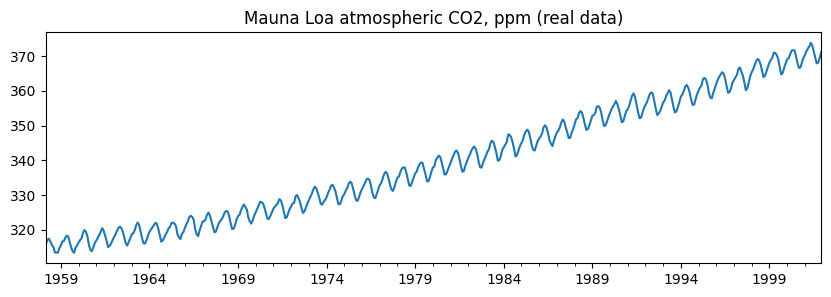

In [20]:
def load_series():
    try:
        import statsmodels.api as sm
        co2 = sm.datasets.co2.load_pandas().data["co2"]                 # weekly, bundled with statsmodels (no internet needed)
        s = co2.resample("MS").mean().interpolate()                     # monthly mean, fill small gaps
        return s, "Mauna Loa atmospheric CO2, ppm (real data)"
    except Exception as e:
        print("statsmodels data unavailable -> synthetic series. (", type(e).__name__, ")")
        t = np.arange(526); rng = np.random.default_rng(0)
        s = pd.Series(315 + 0.12 * t + 3 * np.sin(2 * np.pi * t / 12) + rng.normal(0, 0.3, len(t)),
                      index=pd.date_range("1958-03-01", periods=len(t), freq="MS"))
        return s, "synthetic trend + seasonality"

series, TS_SOURCE = load_series()
print("Data source:", TS_SOURCE, "| points:", len(series))
series.plot(figsize=(10, 3), title=TS_SOURCE); plt.show()

### ✏️ Task C1: Chronological split + naive baselines
- `train_end` = index where the last 20% of the series starts (`int(0.8 * len(series))`).
- Compute the **MAE** (`mean_absolute_error`) on the test period of:
  - **naive**: predict `y[t] = y[t-1]`
  - **seasonal naive**: predict `y[t] = y[t-12]`

In [22]:
vals = series.values.astype("float32")
n = len(vals)
WINDOW = 24

# TODO 1: train_end (the index separating first 80% of data)
train_end = int(0.8 * n)

# TODO 2: test targets and the two naive predictions for the indices train_end ... n-1
y_true = vals[train_end:]
pred_naive = vals[train_end - 1 : n - 1]
pred_seasonal = vals[train_end - 12 : n - 12]

mae = {"naive (last month)": mean_absolute_error(y_true, pred_naive),
       "seasonal naive (12 months ago)": mean_absolute_error(y_true, pred_seasonal)}
print({k: round(v, 3) for k, v in mae.items()})

{'naive (last month)': 1.13, 'seasonal naive (12 months ago)': 1.631}


In [ ]:
# ✅ Check C1
assert train_end == int(0.8 * n) and len(y_true) == len(pred_naive) == len(pred_seasonal) == n - train_end
print("✔ passed")

### ✏️ Task C2: First attempt: LSTM on the raw (scaled) series
1. Scale with `StandardScaler` **fitted on the training part only**.
2. Windows are built for you (`make_xy`, which uses `timeseries_dataset_from_array`). Select training windows (target index `< train_end`) and test windows with a boolean mask.
3. Model: `LSTM(32) → Dense(1)`, `mse` loss, `adam`, up to 40 epochs, `EarlyStopping(patience=5, restore_best_weights=True)`, `validation_split=0.15` (Keras takes the **last** 15%, which is chronological: good).
4. Inverse-transform the predictions and compute test MAE.

{'naive (last month)': 1.13, 'seasonal naive (12 months ago)': 1.631, 'LSTM on raw series': 12.268}


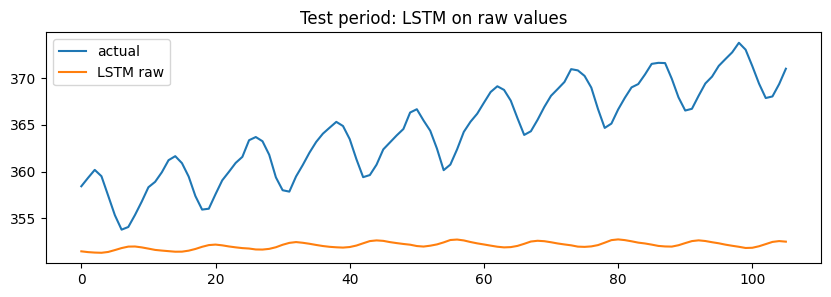

In [23]:
def make_xy(values, window):
    '''values: (n, 1) array -> X (N, window, 1), y (N, 1), where y[j] follows X[j].'''
    ds = keras.utils.timeseries_dataset_from_array(values[:-1], values[window:], sequence_length=window, batch_size=len(values))
    X, y = next(iter(ds))
    return X.numpy(), y.numpy()

EPOCHS_TS = 8 if FAST else 40
# TODO 1: scaler fitted on vals[:train_end] only; scaled = scaler.transform(all values)  (shape (n, 1))
scaler = StandardScaler()
scaler.fit(vals[:train_end].reshape(-1, 1))
scaled = scaler.transform(vals.reshape(-1, 1))

X, y = make_xy(scaled, WINDOW)
target_idx = np.arange(len(X)) + WINDOW          # position in the original series of each target
train_mask = target_idx < train_end

# TODO 2: split X, y with the mask into X_tr, y_tr, X_te, y_te
X_tr, y_tr = X[train_mask], y[train_mask]
X_te, y_te = X[~train_mask], y[~train_mask]

# TODO 3: build + compile + fit the model
raw_model = keras.Sequential([
    layers.Input(shape=(WINDOW, 1)),
    layers.LSTM(32),
    layers.Dense(1)
])
raw_model.compile(optimizer="adam", loss="mse")
early_stop_ts = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)
raw_model.fit(
    X_tr, y_tr,
    epochs=EPOCHS_TS,
    validation_split=0.15,
    callbacks=[early_stop_ts],
    verbose=0
)

# TODO 4: predict on X_te, inverse_transform, ravel -> pred_lstm_raw
pred_lstm_raw = scaler.inverse_transform(raw_model.predict(X_te, verbose=0)).ravel()
mae["LSTM on raw series"] = mean_absolute_error(y_true, pred_lstm_raw)
print({k: round(v, 3) for k, v in mae.items()})

plt.figure(figsize=(10, 3)); plt.plot(y_true, label="actual"); plt.plot(pred_lstm_raw, label="LSTM raw")
plt.legend(); plt.title("Test period: LSTM on raw values"); plt.show()

In [ ]:
# ✅ Check C2
assert len(pred_lstm_raw) == len(y_true) and X_tr.shape[1:] == (WINDOW, 1)
print("✔ passed")

**Question C2:** compare the LSTM's MAE with the naive baselines and look at the plot. Where does the LSTM go wrong (level? trend? season?) and why do you think so?

**Your answer:**
The LSTM performs significantly worse (MAE = 12.268) than both the naive (1.130) and seasonal naive (1.631) baselines. Looking at the plot, the LSTM completely misses the **upward trend**, and instead outputs a flat line centered around the maximum values of the training set. This happens because the activation functions inside the LSTM (specifically `tanh`) squash outputs and are incapable of extrapolating an ever-rising trend to range limits that were never seen during training.

### ✏️ Task C3: The expert fix, forecast the *change*, not the level
1. Compute first differences `d = series.diff()` (use pandas) and drop the first NaN → `d_vals`.
2. Scale with a `StandardScaler` fitted on the training differences only (`d_vals[:train_end - 1]`).
3. Build windows with `make_xy` (the target of sample *j* is the change at series position `j + WINDOW + 1`).
4. Train the **same** LSTM architecture on the differences.
5. Convert back: `prediction[t] = vals[t-1] + predicted_change[t]`.

In [24]:
# TODO 1: d_vals (shape (n-1, 1)) = first differences of vals
d_vals = np.diff(vals).reshape(-1, 1)

# TODO 2: scaler fitted on d_vals[:train_end - 1]; d_scaled = scaler.transform(d_vals)
d_scaler = StandardScaler()
d_scaler.fit(d_vals[:train_end - 1])
d_scaled = d_scaler.transform(d_vals)

Xd, yd = make_xy(d_scaled, WINDOW)
d_target_idx = np.arange(len(Xd)) + WINDOW + 1   # position in the ORIGINAL series
d_train_mask = d_target_idx < train_end

# TODO 3: split into Xd_tr, yd_tr, Xd_te
Xd_tr, yd_tr = Xd[d_train_mask], yd[d_train_mask]
Xd_te = Xd[~d_train_mask]

# TODO 4: model + compile + fit (same settings as C2)
diff_model = keras.Sequential([
    layers.Input(shape=(WINDOW, 1)),
    layers.LSTM(32),
    layers.Dense(1)
])
diff_model.compile(optimizer="adam", loss="mse")
early_stop_ts2 = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)
diff_model.fit(
    Xd_tr, yd_tr,
    epochs=EPOCHS_TS,
    validation_split=0.15,
    callbacks=[early_stop_ts2],
    verbose=0
)

# TODO 5: predicted change (inverse scaled) -> pred_lstm_diff = previous true value + predicted change
pred_change_scaled = diff_model.predict(Xd_te, verbose=0)
pred_change = d_scaler.inverse_transform(pred_change_scaled).ravel()
pred_lstm_diff = vals[train_end - 1 : n - 1] + pred_change

mae["LSTM on differences"] = mean_absolute_error(y_true, pred_lstm_diff)
print({k: round(v, 3) for k, v in mae.items()})

{'naive (last month)': 1.13, 'seasonal naive (12 months ago)': 1.631, 'LSTM on raw series': 12.268, 'LSTM on differences': 0.289}


In [ ]:
# ✅ Check C3
assert len(pred_lstm_diff) == len(y_true)
assert mae["LSTM on differences"] < mae["LSTM on raw series"], "Differencing should help the LSTM on this trending series"
print("✔ passed")

### ✏️ Task C4: The honest challenger, Ridge regression on the same windows
Fit scikit-learn `Ridge(alpha=1.0)` on the **flattened** difference windows (`Xd_tr.reshape(len(Xd_tr), -1)`, `yd_tr.ravel()`), predict the test windows, and convert back exactly as in C3.

,test MAE
Ridge on differences,0.257
LSTM on differences,0.289
naive (last month),1.130
seasonal naive (12 months ago),1.631
LSTM on raw series,12.268


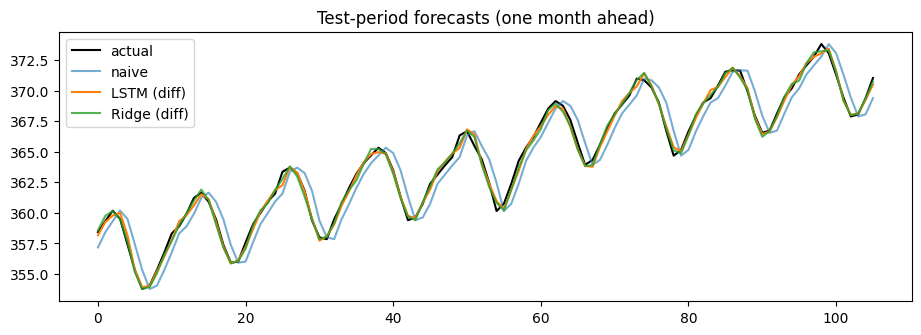

In [25]:
# TODO: ridge model -> fit -> predicted change -> inverse scale -> pred_ridge (levels)
ridge = Ridge(alpha=1.0)
# Flatten the 3D windows (N, WINDOW, 1) into 2D (N, WINDOW) for scikit-learn
Xd_tr_flat = Xd_tr.reshape(len(Xd_tr), -1)
Xd_te_flat = Xd_te.reshape(len(Xd_te), -1)

ridge.fit(Xd_tr_flat, yd_tr.ravel())
pred_change_scaled_ridge = ridge.predict(Xd_te_flat)
pred_change_ridge = d_scaler.inverse_transform(pred_change_scaled_ridge.reshape(-1, 1)).ravel()

pred_ridge = vals[train_end - 1 : n - 1] + pred_change_ridge

mae["Ridge on differences"] = mean_absolute_error(y_true, pred_ridge)
result = pd.Series(mae).sort_values().round(3).to_frame("test MAE")
display(result)

plt.figure(figsize=(11, 3.5))
plt.plot(y_true, "k", label="actual"); plt.plot(pred_naive, label="naive", alpha=.6)
plt.plot(pred_lstm_diff, label="LSTM (diff)"); plt.plot(pred_ridge, label="Ridge (diff)", alpha=.8)
plt.legend(); plt.title("Test-period forecasts (one month ahead)"); plt.show()

In [ ]:
# ✅ Check C4
assert len(pred_ridge) == len(y_true)
print("✔ passed")

### 🧠 Decision C (write 4–6 sentences)
Look at the table.
1. Which model is best, and by how much does the LSTM beat (or lose to) the naive baseline and Ridge?
2. If this were *one* series with 500 points, would you deploy an LSTM?
3. Describe a time-series project where you **would** choose an LSTM (hint: many series, extra input variables, nonlinear patterns, lots of data).

**Your answer:**
1. The simple **Ridge Regression model on differences is the best model**, achieving a test MAE of **0.257**. The LSTM on differences is slightly worse (MAE = 0.289), meaning it loses to Ridge by 0.032, but both models drastically outperform the naive baseline of 1.130.
2. If I were forecasting a single series of 500 points, I would **never** deploy an LSTM. A simple linear model or statistical model (like Ridge, ARIMA, or ETS) is faster, less prone to overfitting on small data, easier to tune, and completely explainable.
3. I **would** choose an LSTM for a complex time-series project like **predicting hourly product demand for thousands of retail stores**. In this scenario, we have millions of data points, multiple interacting series, external variables (like promotions, holidays, local weather, and prices), and highly non-linear relationships that a simple linear model cannot model.

---
# Final section: Be the consultant

For each scenario, decide **LSTM / not LSTM**, name what you would try **first**, and justify in 2–3 sentences. Write your answers in the table.

| # | Scenario | Your decision & first thing to try |
|---|---|---|
| 1 | Predict which of 1 million bank customers will churn from 30 account columns (age, balance, products ...) | **Not LSTM.** Try **XGBoost / LightGBM** first. Tabular datasets lack sequential ordering, and gradient-boosted decision trees routinely outperform deep learning on heterogeneous columns. |
| 2 | Detect failing wind turbines from 1 hour of 50 Hz vibration + temperature readings | **LSTM (or 1D-CNN).** Try **1D-CNN** or a **standard LSTM classifier** first. This is high-frequency multivariate sensor data where temporal trends and order matter heavily to recognize physical fault signals. |
| 3 | Classify 20-page legal contracts into 12 categories | **Not LSTM.** Try a **pre-trained Transformer (like RoBERTa or Longformer)** first. LSTMs suffer from vanishing gradients over long spans of thousands of tokens, whereas attention mechanisms handle long document context much better. |
| 4 | Phone keyboard word suggestion that works offline | **LSTM.** Try a **small GRU / LSTM model** first. For resource-constrained on-device settings, a tiny language model provides a great balance between accuracy, ultra-low latency, and small memory foot-print. |
| 5 | Forecast daily demand for 5000 stores × 200 products with promotions, holidays and weather | **LSTM.** Try **DeepAR / Seq2Seq LSTM** first. This is a massive-scale time-series problem with external covariates and non-linear patterns across millions of series where deep learning shines. |
| 6 | Forecast the monthly revenue of one small shop (3 years of data) | **Not LSTM.** Try **SARIMA** or **seasonal naive** first. With only 36 monthly data points, deep learning models will immediately overfit, while simple statistical methods handle the seasonal patterns reliably. |
| 7 | Product-review sentiment for an app with 10 000 reviews and a tight latency budget | **Not LSTM.** Try **TF-IDF + Logistic Regression** first. Given the low review count and a strict latency budget, a sparse linear model achieves high accuracy instantly with minimal compute cost. |